# 02 - Preprocessing et Feature Engineering

## Objectif du notebook

Ce notebook prend les 8 fichiers ADS-B bruts placés dans `data/raw/` et produit un fichier propre et enrichi en features.

Entrée :

`data/raw/*.csv`

Sorties :

1. `data/interim/clean_all_8h.csv`
2. `data/processed/features_clean.csv`

Dans ce notebook, nous faisons :

- nettoyage des fichiers bruts ;
- concaténation des fichiers nettoyés ;
- tri par avion et par temps ;
- création de trajectoires continues ;
- resampling temporel à 10 secondes ;
- feature engineering.

Dans ce notebook, nous ne faisons pas encore :

- création des targets futures ;
- train / validation / test split ;
- normalisation ;
- PCA ;
- modèles ML ;
- modèles DL.

# 1. Initialisation de l’environnement

Nous commençons par monter Google Drive et importer les bibliothèques nécessaires.

Le projet est stocké dans Google Drive afin de conserver les fichiers même après la fermeture de Google Colab.

In [ ]:
# Monter Google Drive pour accéder au projet
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Imports principaux
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Configuration d'affichage pour rendre les tableaux plus lisibles
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

# 2. Définition des chemins du projet

Nous définissons les chemins principaux du projet.

Les fichiers bruts se trouvent dans :

`data/raw/`

Le fichier nettoyé intermédiaire sera sauvegardé dans :

`data/interim/`

Les résumés de nettoyage seront sauvegardés dans :

`results/metrics/`

In [ ]:
# Chemin principal du projet dans Google Drive
PROJECT_DIR = Path("/content/drive/MyDrive/aircraft-trajectory-prediction")

# Dossiers de données
RAW_DIR = PROJECT_DIR / "data" / "raw"
INTERIM_DIR = PROJECT_DIR / "data" / "interim"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

# Vérification des chemins
print("Projet existe :", PROJECT_DIR.exists())
print("Dossier raw existe :", RAW_DIR.exists())
print("Dossier interim existe :", INTERIM_DIR.exists())
print("Dossier processed existe :", PROCESSED_DIR.exists())

Projet existe : True
Dossier raw existe : True
Dossier interim existe : True
Dossier processed existe : True


In [ ]:
# Dossier des résultats
RESULTS_DIR = PROJECT_DIR / "results"
METRICS_DIR = RESULTS_DIR / "metrics"

print("Dossier results existe :", RESULTS_DIR.exists())
print("Dossier metrics existe :", METRICS_DIR.exists())

Dossier results existe : True
Dossier metrics existe : True


# 3. Vérification des fichiers bruts disponibles

Nous vérifions que les fichiers CSV bruts sont bien présents dans le dossier `data/raw/`.

Dans notre cas, nous travaillons avec 8 fichiers horaires.

In [ ]:
# Récupérer tous les fichiers CSV dans data/raw/
csv_files = sorted(RAW_DIR.glob("*.csv"))

print("Nombre de fichiers CSV trouvés :", len(csv_files))

for file in csv_files:
    print("-", file.name)

Nombre de fichiers CSV trouvés : 8
- states_2017-07-03-10.csv
- states_2017-07-03-11.csv
- states_2017-07-03-12.csv
- states_2017-07-03-13.csv
- states_2017-07-03-14.csv
- states_2017-07-03-15.csv
- states_2017-07-03-16.csv
- states_2017-07-03-17.csv


In [ ]:
# Vérification simple
if len(csv_files) == 0:
    raise FileNotFoundError("Aucun fichier CSV trouvé dans data/raw/.")

if len(csv_files) != 8:
    print("Attention : le nombre de fichiers trouvé est différent de 8.")
    print("Vérifie que les 8 fichiers horaires sont bien dans data/raw/.")
else:
    print("Les 8 fichiers horaires sont bien détectés.")

Les 8 fichiers horaires sont bien détectés.


# 4. Définition des colonnes utiles

Nous gardons uniquement les colonnes nécessaires pour construire les trajectoires.

Ces colonnes permettent de connaître :

- l’avion ;
- le temps ;
- la position ;
- l’altitude ;
- la vitesse ;
- la direction ;
- la vitesse verticale.

Cette sélection réduit la mémoire utilisée et garde le dataset plus simple.

In [ ]:
# Colonnes nécessaires pour le preprocessing
USEFUL_COLUMNS = [
    "time",          # timestamp Unix en secondes
    "icao24",        # identifiant unique de l'avion
    "lat",           # latitude
    "lon",           # longitude
    "velocity",      # vitesse sol en m/s
    "heading",       # direction de l'avion en degrés
    "vertrate",      # vitesse verticale en m/s
    "baroaltitude",  # altitude barométrique en mètres
    "geoaltitude"    # altitude géométrique en mètres
]

In [ ]:
# Vérifier que toutes les colonnes utiles existent dans chaque fichier
for file in csv_files:
    df_sample = pd.read_csv(file, nrows=5)

    missing_cols = [
        col for col in USEFUL_COLUMNS
        if col not in df_sample.columns
    ]

    print("\nFichier :", file.name)

    if len(missing_cols) == 0:
        print("Toutes les colonnes utiles sont présentes.")
    else:
        print("Colonnes manquantes :", missing_cols)


Fichier : states_2017-07-03-10.csv
Toutes les colonnes utiles sont présentes.

Fichier : states_2017-07-03-11.csv
Toutes les colonnes utiles sont présentes.

Fichier : states_2017-07-03-12.csv
Toutes les colonnes utiles sont présentes.

Fichier : states_2017-07-03-13.csv
Toutes les colonnes utiles sont présentes.

Fichier : states_2017-07-03-14.csv
Toutes les colonnes utiles sont présentes.

Fichier : states_2017-07-03-15.csv
Toutes les colonnes utiles sont présentes.

Fichier : states_2017-07-03-16.csv
Toutes les colonnes utiles sont présentes.

Fichier : states_2017-07-03-17.csv
Toutes les colonnes utiles sont présentes.


# 5. Fonction de nettoyage d’un fichier

Nous définissons une fonction qui nettoie un seul fichier CSV.

Cette fonction reprend les bonnes parties de l’ancien notebook :

- sélection des colonnes utiles ;
- suppression des lignes sans identifiant avion ;
- suppression des lignes sans position ;
- suppression des lignes sans vitesse, heading ou vertical rate ;
- fusion de `geoaltitude` et `baroaltitude` ;
- filtrage des valeurs physiquement impossibles ;
- suppression des doublons ;
- tri par avion et par temps.

Correction importante par rapport à l’ancien notebook :

Nous nettoyons chaque fichier séparément avant de concaténer les 8 fichiers.

In [ ]:
def clean_one_file(file_path):
    """
    Nettoie un fichier ADS-B OpenSky.

    Paramètre
    ---------
    file_path : Path
        Chemin vers un fichier CSV brut.

    Retour
    ------
    df_clean : DataFrame
        Données nettoyées du fichier.

    summary : dict
        Résumé du nettoyage effectué.
    """

    print("=" * 80)
    print("Nettoyage du fichier :", file_path.name)
    print("=" * 80)

    # ---------------------------------------------------------
    # 1. Charger uniquement les colonnes utiles
    # ---------------------------------------------------------
    # Cela évite de charger des colonnes inutiles et réduit la mémoire utilisée.
    df = pd.read_csv(file_path, usecols=USEFUL_COLUMNS)

    n_initial = len(df)

    # ---------------------------------------------------------
    # 2. Conversion des colonnes numériques
    # ---------------------------------------------------------
    # errors="coerce" transforme les valeurs non numériques en NaN.
    # Ces NaN seront traités ensuite.
    numeric_cols = [
        "time",
        "lat",
        "lon",
        "velocity",
        "heading",
        "vertrate",
        "baroaltitude",
        "geoaltitude"
    ]

    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # ---------------------------------------------------------
    # 3. Nettoyage de l'identifiant avion
    # ---------------------------------------------------------
    # icao24 identifie l'avion.
    # On le convertit en chaîne propre, sans espaces, en minuscules.
    df["icao24"] = df["icao24"].astype("string").str.strip().str.lower()

    # ---------------------------------------------------------
    # 4. Suppression des lignes sans time ou sans icao24
    # ---------------------------------------------------------
    # Sans time, on ne connaît pas l'instant de l'observation.
    # Sans icao24, on ne peut pas reconstruire une trajectoire.
    n_before = len(df)

    df = df.dropna(subset=["time", "icao24"])
    df = df[df["icao24"] != ""]

    removed_time_icao = n_before - len(df)

    # ---------------------------------------------------------
    # 5. Création de la colonne datetime
    # ---------------------------------------------------------
    # La colonne time est un timestamp Unix en secondes.
    # datetime est plus lisible pour le tri et l'analyse.
    df["datetime"] = pd.to_datetime(df["time"], unit="s", utc=True)

    # ---------------------------------------------------------
    # 6. Suppression des lignes sans position
    # ---------------------------------------------------------
    # Sans latitude ou longitude, on ne connaît pas la position de l'avion.
    # Ces lignes sont inutilisables pour une trajectoire.
    n_before = len(df)

    df = df.dropna(subset=["lat", "lon"])

    removed_position = n_before - len(df)

    # ---------------------------------------------------------
    # 7. Suppression des lignes sans variables de mouvement
    # ---------------------------------------------------------
    # velocity : vitesse sol en m/s
    # heading  : direction en degrés
    # vertrate : vitesse verticale en m/s
    n_before = len(df)

    df = df.dropna(subset=["velocity", "heading", "vertrate"])

    removed_motion = n_before - len(df)

    # ---------------------------------------------------------
    # 8. Création d'une colonne altitude unique
    # ---------------------------------------------------------
    # Stratégie :
    # - utiliser geoaltitude si disponible ;
    # - sinon utiliser baroaltitude.
    df["altitude"] = df["geoaltitude"].fillna(df["baroaltitude"])

    # Supprimer les lignes où les deux altitudes sont absentes.
    n_before = len(df)

    df = df.dropna(subset=["altitude"])

    removed_altitude = n_before - len(df)

    # ---------------------------------------------------------
    # 9. Filtrage des valeurs physiquement impossibles
    # ---------------------------------------------------------
    # Règles simples :
    # - latitude entre -90 et 90 ;
    # - longitude entre -180 et 180 ;
    # - vitesse positive ou nulle ;
    # - heading entre 0 et 360 ;
    # - altitude dans une plage réaliste en mètres.
    n_before = len(df)

    df = df[
        df["lat"].between(-90, 90) &
        df["lon"].between(-180, 180) &
        (df["velocity"] >= 0) &
        df["heading"].between(0, 360) &
        df["altitude"].between(-500, 20000)
    ]

    removed_invalid = n_before - len(df)

    # ---------------------------------------------------------
    # 10. Suppression des colonnes d'altitude originales
    # ---------------------------------------------------------
    # On garde uniquement la colonne altitude fusionnée.
    df = df.drop(columns=["geoaltitude", "baroaltitude"])

    # ---------------------------------------------------------
    # 11. Ajout du fichier source
    # ---------------------------------------------------------
    # Cette colonne permet de savoir d'où vient chaque ligne.
    df["source_file"] = file_path.name

    # ---------------------------------------------------------
    # 12. Suppression des doublons
    # ---------------------------------------------------------
    n_before = len(df)

    # Doublons exacts
    df = df.drop_duplicates()

    # Doublons même avion au même instant
    df = df.drop_duplicates(
        subset=["icao24", "datetime"],
        keep="first"
    )

    removed_duplicates = n_before - len(df)

    # ---------------------------------------------------------
    # 13. Tri interne du fichier
    # ---------------------------------------------------------
    df = df.sort_values(["icao24", "datetime"]).reset_index(drop=True)

    # ---------------------------------------------------------
    # 14. Réorganisation des colonnes
    # ---------------------------------------------------------
    final_columns = [
        "source_file",
        "time",
        "datetime",
        "icao24",
        "lat",
        "lon",
        "altitude",
        "velocity",
        "heading",
        "vertrate"
    ]

    df = df[final_columns]

    # ---------------------------------------------------------
    # 15. Résumé du nettoyage
    # ---------------------------------------------------------
    summary = {
        "file": file_path.name,
        "initial_rows": n_initial,
        "final_rows": len(df),
        "removed_time_or_icao24": removed_time_icao,
        "removed_position": removed_position,
        "removed_motion": removed_motion,
        "removed_altitude": removed_altitude,
        "removed_invalid_values": removed_invalid,
        "removed_duplicates": removed_duplicates,
        "n_aircraft": df["icao24"].nunique()
    }

    print("Lignes initiales :", f"{n_initial:,}")
    print("Lignes finales :", f"{len(df):,}")
    print("Avions uniques :", f"{df['icao24'].nunique():,}")

    return df, summary

# 6. Nettoyage automatique des fichiers

Nous appliquons maintenant la fonction `clean_one_file()` à tous les fichiers bruts.

Chaque fichier est nettoyé séparément.

Les résultats nettoyés sont stockés dans une liste, puis seront concaténés dans l’étape suivante.

In [ ]:
# Liste qui contiendra les DataFrames nettoyés
clean_parts = []

# Liste qui contiendra les résumés de nettoyage
cleaning_summaries = []

# Application de la fonction de nettoyage à chaque fichier
for file in csv_files:
    df_clean, summary = clean_one_file(file)

    clean_parts.append(df_clean)
    cleaning_summaries.append(summary)

print("Nettoyage terminé.")
print("Nombre de fichiers nettoyés :", len(clean_parts))

Nettoyage du fichier : states_2017-07-03-10.csv
Lignes initiales : 1,684,690
Lignes finales : 1,240,685
Avions uniques : 6,490
Nettoyage du fichier : states_2017-07-03-11.csv
Lignes initiales : 1,849,076
Lignes finales : 1,343,337
Avions uniques : 6,906
Nettoyage du fichier : states_2017-07-03-12.csv
Lignes initiales : 1,970,582
Lignes finales : 1,367,547
Avions uniques : 7,357
Nettoyage du fichier : states_2017-07-03-13.csv
Lignes initiales : 2,159,702
Lignes finales : 1,489,804
Avions uniques : 7,902
Nettoyage du fichier : states_2017-07-03-14.csv
Lignes initiales : 2,267,582
Lignes finales : 1,554,423
Avions uniques : 8,483
Nettoyage du fichier : states_2017-07-03-15.csv
Lignes initiales : 2,314,879
Lignes finales : 1,580,488
Avions uniques : 8,697
Nettoyage du fichier : states_2017-07-03-16.csv
Lignes initiales : 2,324,633
Lignes finales : 1,597,025
Avions uniques : 8,711
Nettoyage du fichier : states_2017-07-03-17.csv
Lignes initiales : 2,296,600
Lignes finales : 1,585,056
Avions 

In [ ]:
# Tableau résumé du nettoyage
cleaning_summary_df = pd.DataFrame(cleaning_summaries)

display(cleaning_summary_df)

,file,initial_rows,final_rows,removed_time_or_icao24,removed_position,removed_motion,removed_altitude,removed_invalid_values,removed_duplicates,n_aircraft
0,states_2017-07-03-10.csv,1684690,1240685,0,360776,60745,21752,732,0,6490
1,states_2017-07-03-11.csv,1849076,1343337,0,422351,60515,22244,629,0,6906
2,states_2017-07-03-12.csv,1970582,1367547,0,505711,68148,28416,760,0,7357
3,states_2017-07-03-13.csv,2159702,1489804,0,573436,68768,26923,771,0,7902
4,states_2017-07-03-14.csv,2267582,1554423,0,612881,72701,26735,842,0,8483
5,states_2017-07-03-15.csv,2314879,1580488,0,635591,69119,28713,968,0,8697
6,states_2017-07-03-16.csv,2324633,1597025,0,633008,66346,27373,881,0,8711
7,states_2017-07-03-17.csv,2296600,1585056,0,605623,70977,33819,1125,0,8954


In [ ]:
# Résumé global du nettoyage
initial_total = cleaning_summary_df["initial_rows"].sum()
final_total = cleaning_summary_df["final_rows"].sum()
removed_total = initial_total - final_total

print("Résumé global du nettoyage")
print("--------------------------")
print("Lignes initiales totales :", f"{initial_total:,}")
print("Lignes finales totales :", f"{final_total:,}")
print("Lignes supprimées au total :", f"{removed_total:,}")
print("Pourcentage de lignes conservées :", round(final_total / initial_total * 100, 2), "%")

Résumé global du nettoyage
--------------------------
Lignes initiales totales : 16,867,744
Lignes finales totales : 11,758,365
Lignes supprimées au total : 5,109,379
Pourcentage de lignes conservées : 69.71 %


# 7. Concaténation des fichiers nettoyés

Après avoir nettoyé chaque fichier séparément, nous les concaténons dans un seul DataFrame.

Cette étape est importante parce qu’un même avion peut apparaître dans plusieurs fichiers horaires.

En concaténant les fichiers nettoyés, nous pouvons reconstruire des trajectoires qui traversent plusieurs heures.

In [ ]:
# Concaténation des fichiers nettoyés
df_clean_all = pd.concat(clean_parts, ignore_index=True)

print("Concaténation terminée.")
print("-----------------------")
print("Nombre total de lignes :", f"{len(df_clean_all):,}")
print("Nombre total de colonnes :", df_clean_all.shape[1])
print("Nombre total d'avions uniques :", f"{df_clean_all['icao24'].nunique():,}")

Concaténation terminée.
-----------------------
Nombre total de lignes : 11,758,365
Nombre total de colonnes : 10
Nombre total d'avions uniques : 20,280


In [ ]:
# Aperçu du dataset concaténé
display(df_clean_all.head())

,source_file,time,datetime,icao24,lat,lon,altitude,velocity,heading,vertrate
0,states_2017-07-03-10.csv,1499076010,2017-07-03 10:00:10+00:00,000023,52.451340,5.664978,281.94,48.939823,230.117315,-0.32512
1,states_2017-07-03-10.csv,1499076020,2017-07-03 10:00:20+00:00,000023,52.449417,5.661469,274.32,49.848004,223.745548,-0.32512
2,states_2017-07-03-10.csv,1499076030,2017-07-03 10:00:30+00:00,000023,52.445114,5.654678,274.32,50.948140,223.363423,-0.32512
3,states_2017-07-03-10.csv,1499076040,2017-07-03 10:00:40+00:00,000023,52.442213,5.650190,289.56,49.869237,222.909841,-0.32512
4,states_2017-07-03-10.csv,1499076050,2017-07-03 10:00:50+00:00,000023,52.440630,5.647757,304.80,46.994959,221.893973,-0.32512


# 8. Suppression des doublons globaux

Même si les doublons ont déjà été supprimés fichier par fichier, nous vérifions à nouveau après concaténation.

Cela permet de supprimer les éventuels doublons situés à la frontière entre deux fichiers horaires.

In [ ]:
# Nombre de lignes avant suppression globale des doublons
n_before = len(df_clean_all)

# Suppression des doublons exacts
df_clean_all = df_clean_all.drop_duplicates()

# Suppression des doublons même avion au même instant
df_clean_all = df_clean_all.drop_duplicates(
    subset=["icao24", "datetime"],
    keep="first"
)

# Nombre de doublons supprimés
n_removed_global_duplicates = n_before - len(df_clean_all)

print("Doublons globaux supprimés :", f"{n_removed_global_duplicates:,}")
print("Nombre de lignes après suppression :", f"{len(df_clean_all):,}")

Doublons globaux supprimés : 0
Nombre de lignes après suppression : 11,758,365


# 9. Tri global par avion et par temps

Nous trions maintenant toutes les observations par :

1. identifiant avion `icao24` ;
2. temps `datetime`.

Ce tri est indispensable avant de construire les trajectoires.

Une trajectoire doit toujours être ordonnée chronologiquement.

In [ ]:
# Tri global du dataset concaténé
df_clean_all = df_clean_all.sort_values(
    ["icao24", "datetime"]
).reset_index(drop=True)

print("Données triées globalement par avion et par temps.")

Données triées globalement par avion et par temps.


In [ ]:
# Vérification visuelle du tri
display(
    df_clean_all[
        ["icao24", "datetime", "lat", "lon", "altitude", "velocity", "heading"]
    ].head(10)
)

,icao24,datetime,lat,lon,altitude,velocity,heading
0,000001,2017-07-03 11:40:20+00:00,51.997686,6.827689,99.06,35.436940,279.188836
1,000001,2017-07-03 11:40:30+00:00,51.997174,6.820391,243.84,34.494611,252.645975
2,000001,2017-07-03 11:40:40+00:00,51.996185,6.816864,243.84,33.972785,237.994617
3,000001,2017-07-03 11:40:50+00:00,51.996185,6.816864,243.84,34.066138,231.745580
4,000001,2017-07-03 11:41:00+00:00,51.991837,6.809464,281.94,35.436940,230.300927
5,000001,2017-07-03 11:41:10+00:00,51.990463,6.805649,281.94,35.436940,230.300927
6,000001,2017-07-03 11:41:20+00:00,51.988495,6.799698,304.80,40.379758,235.905022
7,000001,2017-07-03 11:41:30+00:00,51.986572,6.795197,312.42,41.094384,235.713123
8,000001,2017-07-03 11:41:40+00:00,51.984558,6.788531,350.52,41.948484,246.893673
9,000001,2017-07-03 11:41:50+00:00,51.982498,6.783447,365.76,43.836546,234.071498


# 10. Création des trajectoires continues

Un même avion peut apparaître dans plusieurs fichiers horaires.

Cependant, un même `icao24` ne représente pas toujours une seule trajectoire continue.

Exemple :

- avion observé à 10h00 ;
- plus aucune observation pendant longtemps ;
- avion revu à 12h00.

Il ne faut pas relier ces deux morceaux comme une seule trajectoire.

Nous créons donc une colonne :

`trajectory_id`

Une nouvelle trajectoire commence lorsqu’il y a un grand écart temporel entre deux observations successives du même avion.

Ici, nous utilisons un seuil de 5 minutes.

In [ ]:
# Calcul de l'écart temporel entre deux observations successives du même avion
df_clean_all["time_gap_sec"] = (
    df_clean_all
    .groupby("icao24")["datetime"]
    .diff()
    .dt.total_seconds()
)

# Le premier point de chaque avion n'a pas de point précédent.
# On remplace donc le NaN par 0 pour faciliter la lecture.
df_clean_all["time_gap_sec"] = df_clean_all["time_gap_sec"].fillna(0)

# Seuil de coupure :
# Si l'avion disparaît pendant plus de 5 minutes,
# on considère qu'une nouvelle trajectoire commence.
GAP_THRESHOLD = 300  # secondes = 5 minutes

# True si :
# - c'est le premier point de l'avion ;
# - ou si l'écart avec le point précédent dépasse 5 minutes.
df_clean_all["new_trajectory"] = (
    (df_clean_all["time_gap_sec"] == 0) |
    (df_clean_all["time_gap_sec"] > GAP_THRESHOLD)
)

# Numéro de segment pour chaque avion
df_clean_all["trajectory_segment"] = (
    df_clean_all
    .groupby("icao24")["new_trajectory"]
    .cumsum()
)

# Identifiant final de trajectoire continue
df_clean_all["trajectory_id"] = (
    df_clean_all["icao24"].astype(str) + "_" +
    df_clean_all["trajectory_segment"].astype(str)
)

print("Création des trajectoires continues terminée.")
print("Nombre d'avions uniques :", f"{df_clean_all['icao24'].nunique():,}")
print("Nombre de trajectoires continues :", f"{df_clean_all['trajectory_id'].nunique():,}")

Création des trajectoires continues terminée.
Nombre d'avions uniques : 20,280
Nombre de trajectoires continues : 41,523


In [ ]:
# Aperçu des trajectoires créées
display(
    df_clean_all[
        ["icao24", "trajectory_id", "datetime", "time_gap_sec", "new_trajectory"]
    ].head(20)
)

,icao24,trajectory_id,datetime,time_gap_sec,new_trajectory
0,000001,000001_1,2017-07-03 11:40:20+00:00,0.0,True
1,000001,000001_1,2017-07-03 11:40:30+00:00,10.0,False
2,000001,000001_1,2017-07-03 11:40:40+00:00,10.0,False
3,000001,000001_1,2017-07-03 11:40:50+00:00,10.0,False
4,000001,000001_1,2017-07-03 11:41:00+00:00,10.0,False
5,000001,000001_1,2017-07-03 11:41:10+00:00,10.0,False
6,000001,000001_1,2017-07-03 11:41:20+00:00,10.0,False
7,000001,000001_1,2017-07-03 11:41:30+00:00,10.0,False
8,000001,000001_1,2017-07-03 11:41:40+00:00,10.0,False
9,000001,000001_1,2017-07-03 11:41:50+00:00,10.0,False


# 11. Suppression des trajectoires trop courtes

Les trajectoires avec très peu de points ne sont pas utiles pour le resampling ou la prédiction.

Nous gardons seulement les trajectoires contenant au moins 30 points.

Ce seuil permet de supprimer les trajectoires trop courtes ou peu exploitables.

In [ ]:
# Nombre minimum de points requis pour garder une trajectoire
MIN_POINTS_PER_TRAJECTORY = 30

# Nombre de lignes et de trajectoires avant filtrage
n_rows_before = len(df_clean_all)
n_traj_before = df_clean_all["trajectory_id"].nunique()

# Calcul de la longueur de chaque trajectoire
trajectory_lengths = df_clean_all.groupby("trajectory_id").size()

# Sélection des trajectoires suffisamment longues
valid_trajectories = trajectory_lengths[
    trajectory_lengths >= MIN_POINTS_PER_TRAJECTORY
].index

# Filtrage du dataset
df_clean_all = df_clean_all[
    df_clean_all["trajectory_id"].isin(valid_trajectories)
].reset_index(drop=True)

# Nombre de lignes et trajectoires après filtrage
n_rows_after = len(df_clean_all)
n_traj_after = df_clean_all["trajectory_id"].nunique()

print("Filtrage des trajectoires trop courtes")
print("--------------------------------------")
print("Minimum de points par trajectoire :", MIN_POINTS_PER_TRAJECTORY)
print("Trajectoires avant :", f"{n_traj_before:,}")
print("Trajectoires après :", f"{n_traj_after:,}")
print("Trajectoires supprimées :", f"{n_traj_before - n_traj_after:,}")
print("Lignes avant :", f"{n_rows_before:,}")
print("Lignes après :", f"{n_rows_after:,}")
print("Lignes supprimées :", f"{n_rows_before - n_rows_after:,}")

Filtrage des trajectoires trop courtes
--------------------------------------
Minimum de points par trajectoire : 30
Trajectoires avant : 41,523
Trajectoires après : 40,205
Trajectoires supprimées : 1,318
Lignes avant : 11,758,365
Lignes après : 11,740,410
Lignes supprimées : 17,955


In [ ]:
# Distribution de la longueur des trajectoires restantes
trajectory_lengths_after = df_clean_all.groupby("trajectory_id").size()

display(trajectory_lengths_after.describe().round(2))

,0
count,40205.00
mean,292.01
std,253.41
min,30.00
25%,106.00
50%,214.00
75%,396.00
max,2868.00


# 12. Nettoyage des colonnes auxiliaires

Les colonnes `new_trajectory` et `trajectory_segment` ont servi à créer `trajectory_id`.

Elles ne sont plus nécessaires pour la suite.

Nous les supprimons pour garder un dataset plus propre.

In [ ]:
# Suppression des colonnes auxiliaires utilisées uniquement pour créer trajectory_id
columns_to_drop = ["new_trajectory", "trajectory_segment"]

df_clean_all = df_clean_all.drop(columns=columns_to_drop)

print("Colonnes auxiliaires supprimées.")
print("Colonnes restantes :")
print(list(df_clean_all.columns))

Colonnes auxiliaires supprimées.
Colonnes restantes :
['source_file', 'time', 'datetime', 'icao24', 'lat', 'lon', 'altitude', 'velocity', 'heading', 'vertrate', 'time_gap_sec', 'trajectory_id']


# 13. Réorganisation des colonnes finales

Nous réorganisons les colonnes pour obtenir un dataset clair et lisible.

La colonne `trajectory_id` est placée près de `icao24`, car elle sera utilisée dans l’étape suivante.

In [ ]:
# Organisation propre des colonnes avant sauvegarde
final_columns = [
    "source_file",
    "time",
    "datetime",
    "icao24",
    "trajectory_id",
    "time_gap_sec",
    "lat",
    "lon",
    "altitude",
    "velocity",
    "heading",
    "vertrate"
]

df_clean_all = df_clean_all[final_columns]

display(df_clean_all.head())

,source_file,time,datetime,icao24,trajectory_id,time_gap_sec,lat,lon,altitude,velocity,heading,vertrate
0,states_2017-07-03-11.csv,1499082020,2017-07-03 11:40:20+00:00,000001,000001_1,0.0,51.997686,6.827689,99.06,35.436940,279.188836,-0.32512
1,states_2017-07-03-11.csv,1499082030,2017-07-03 11:40:30+00:00,000001,000001_1,10.0,51.997174,6.820391,243.84,34.494611,252.645975,-0.32512
2,states_2017-07-03-11.csv,1499082040,2017-07-03 11:40:40+00:00,000001,000001_1,10.0,51.996185,6.816864,243.84,33.972785,237.994617,-0.32512
3,states_2017-07-03-11.csv,1499082050,2017-07-03 11:40:50+00:00,000001,000001_1,10.0,51.996185,6.816864,243.84,34.066138,231.745580,-0.32512
4,states_2017-07-03-11.csv,1499082060,2017-07-03 11:41:00+00:00,000001,000001_1,10.0,51.991837,6.809464,281.94,35.436940,230.300927,-0.32512


# 14. Vérification finale du dataset nettoyé

Avant de sauvegarder, nous vérifions que le dataset est cohérent.

Nous contrôlons :

- le nombre de lignes ;
- le nombre de colonnes ;
- le nombre d’avions uniques ;
- le nombre de trajectoires continues ;
- la période couverte ;
- les valeurs manquantes ;
- les statistiques des colonnes principales ;
- les règles physiques simples.

In [ ]:
print("Résumé final du dataset nettoyé")
print("--------------------------------")
print("Nombre de lignes :", f"{len(df_clean_all):,}")
print("Nombre de colonnes :", df_clean_all.shape[1])
print("Nombre d'avions uniques :", f"{df_clean_all['icao24'].nunique():,}")
print("Nombre de trajectoires :", f"{df_clean_all['trajectory_id'].nunique():,}")
print("Période :", df_clean_all["datetime"].min(), "→", df_clean_all["datetime"].max())

Résumé final du dataset nettoyé
--------------------------------
Nombre de lignes : 11,740,410
Nombre de colonnes : 12
Nombre d'avions uniques : 19,861
Nombre de trajectoires : 40,205
Période : 2017-07-03 10:00:00+00:00 → 2017-07-03 17:59:50+00:00


In [ ]:
print("Valeurs manquantes restantes")
print("----------------------------")

missing_after_cleaning = df_clean_all.isna().sum().reset_index()
missing_after_cleaning.columns = ["column", "missing_count"]

display(missing_after_cleaning)

Valeurs manquantes restantes
----------------------------


,column,missing_count
0,source_file,0
1,time,0
2,datetime,0
3,icao24,0
4,trajectory_id,0
5,time_gap_sec,0
6,lat,0
7,lon,0
8,altitude,0
9,velocity,0


In [ ]:
print("Statistiques des colonnes principales")
print("-------------------------------------")

main_cols = [
    "lat",
    "lon",
    "altitude",
    "velocity",
    "heading",
    "vertrate",
    "time_gap_sec"
]

display(df_clean_all[main_cols].describe().round(2))

Statistiques des colonnes principales
-------------------------------------


,lat,lon,altitude,velocity,heading,vertrate,time_gap_sec
count,11740410.00,11740410.00,11740410.00,11740410.00,11740410.00,11740410.00,11740410.00
mean,41.79,-19.82,8083.30,194.29,189.35,-0.14,18.71
std,14.54,57.38,4108.13,66.34,101.49,29.17,265.83
min,-46.73,-156.76,-449.58,0.00,-0.00,-2087.88,0.00
25%,38.81,-78.57,4389.12,161.71,102.01,-0.33,10.00
50%,43.63,1.62,10050.78,216.96,199.49,0.00,10.00
75%,49.96,13.56,11399.52,237.22,277.54,0.33,10.00
max,68.03,178.28,19941.54,2901.48,359.94,1775.46,27710.00


In [ ]:
# Vérifications de cohérence physique
checks = {
    "lat entre -90 et 90": df_clean_all["lat"].between(-90, 90).all(),
    "lon entre -180 et 180": df_clean_all["lon"].between(-180, 180).all(),
    "velocity >= 0": (df_clean_all["velocity"] >= 0).all(),
    "heading entre 0 et 360": df_clean_all["heading"].between(0, 360).all(),
    "altitude entre -500 et 20000 m": df_clean_all["altitude"].between(-500, 20000).all()
}

for rule, status in checks.items():
    print(rule, ":", "OK" if status else "PROBLÈME")

lat entre -90 et 90 : OK
lon entre -180 et 180 : OK
velocity >= 0 : OK
heading entre 0 et 360 : OK
altitude entre -500 et 20000 m : OK


In [ ]:
# Vérification de la longueur des trajectoires
trajectory_size_summary = (
    df_clean_all
    .groupby("trajectory_id")
    .size()
    .describe()
    .round(2)
)

print("Distribution de la longueur des trajectoires")
print("--------------------------------------------")
display(trajectory_size_summary)

Distribution de la longueur des trajectoires
--------------------------------------------


,0
count,40205.00
mean,292.01
std,253.41
min,30.00
25%,106.00
50%,214.00
75%,396.00
max,2868.00


# 15. Sauvegarde des résultats du nettoyage

Nous sauvegardons deux éléments :

1. le dataset nettoyé dans `data/interim/clean_all_8h.csv` ;
2. le résumé du nettoyage dans `results/metrics/cleaning_summary.csv`.

Le fichier `clean_all_8h.csv` sera utilisé dans la prochaine étape pour le resampling temporel.

In [ ]:
# Création des dossiers de sortie si nécessaire
INTERIM_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

# Chemins de sortie
clean_output_path = INTERIM_DIR / "clean_all_8h.csv"
summary_output_path = METRICS_DIR / "cleaning_summary.csv"

# Sauvegarde du dataset nettoyé
df_clean_all.to_csv(clean_output_path, index=False)

# Sauvegarde du résumé de nettoyage
cleaning_summary_df.to_csv(summary_output_path, index=False)

print("Fichier nettoyé sauvegardé avec succès.")
print("Chemin :", clean_output_path)
print("Shape :", df_clean_all.shape)

print("\nRésumé du nettoyage sauvegardé avec succès.")
print("Chemin :", summary_output_path)

Fichier nettoyé sauvegardé avec succès.
Chemin : /content/drive/MyDrive/aircraft-trajectory-prediction/data/interim/clean_all_8h.csv
Shape : (11740410, 12)

Résumé du nettoyage sauvegardé avec succès.
Chemin : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/cleaning_summary.csv


# 16. Vérification du fichier sauvegardé

Nous relisons rapidement le fichier sauvegardé pour vérifier qu’il est bien accessible et correctement enregistré.

In [ ]:
# Relecture rapide du fichier sauvegardé
df_check = pd.read_csv(clean_output_path, nrows=5)

display(df_check)

,source_file,time,datetime,icao24,trajectory_id,time_gap_sec,lat,lon,altitude,velocity,heading,vertrate
0,states_2017-07-03-11.csv,1499082020,2017-07-03 11:40:20+00:00,1,000001_1,0.0,51.997686,6.827689,99.06,35.436940,279.188836,-0.32512
1,states_2017-07-03-11.csv,1499082030,2017-07-03 11:40:30+00:00,1,000001_1,10.0,51.997174,6.820391,243.84,34.494611,252.645975,-0.32512
2,states_2017-07-03-11.csv,1499082040,2017-07-03 11:40:40+00:00,1,000001_1,10.0,51.996185,6.816864,243.84,33.972785,237.994617,-0.32512
3,states_2017-07-03-11.csv,1499082050,2017-07-03 11:40:50+00:00,1,000001_1,10.0,51.996185,6.816864,243.84,34.066138,231.745580,-0.32512
4,states_2017-07-03-11.csv,1499082060,2017-07-03 11:41:00+00:00,1,000001_1,10.0,51.991837,6.809464,281.94,35.436940,230.300927,-0.32512


In [ ]:
print("Le fichier clean_all_8h.csv est prêt pour le resampling.")
print("Chemin :", clean_output_path)

Le fichier clean_all_8h.csv est prêt pour le resampling.
Chemin : /content/drive/MyDrive/aircraft-trajectory-prediction/data/interim/clean_all_8h.csv


# 17. Conclusion du notebook

Dans ce notebook, nous avons réalisé la première étape du preprocessing des données ADS-B.

L’objectif était de transformer les 8 fichiers horaires bruts en un dataset propre, concaténé, trié et structuré en trajectoires continues.

## Ce que nous avons fait

Nous avons commencé par charger les fichiers CSV présents dans le dossier `data/raw/`.

Ensuite, nous avons appliqué les mêmes règles de nettoyage à chaque fichier :

- sélection des colonnes nécessaires à la construction des trajectoires ;
- suppression des lignes sans identifiant avion ;
- suppression des lignes sans temps ;
- suppression des lignes sans latitude ou longitude ;
- suppression des lignes sans vitesse, heading ou vitesse verticale ;
- création d’une colonne unique `altitude` à partir de `geoaltitude` et `baroaltitude` ;
- suppression des lignes sans altitude ;
- filtrage des valeurs physiquement impossibles ;
- suppression des doublons.

Après le nettoyage de chaque fichier, nous avons concaténé les 8 fichiers nettoyés dans un seul dataset global.

Nous avons ensuite trié les données par avion et par temps afin de reconstruire correctement l’ordre chronologique des observations.

Pour éviter de relier artificiellement deux morceaux de vol séparés par un grand trou temporel, nous avons créé une colonne `trajectory_id`.

Cette colonne permet d’identifier chaque trajectoire continue d’un avion.

Enfin, nous avons supprimé les trajectoires trop courtes, car elles ne sont pas suffisamment exploitables pour le resampling et la modélisation.

## Fichier produit

Le fichier nettoyé a été sauvegardé ici :

`data/interim/clean_all_8h.csv`

Ce fichier contient des données :

- nettoyées ;
- concaténées ;
- triées chronologiquement ;
- structurées par trajectoires continues ;
- prêtes pour le resampling temporel.

## Rôle de cette étape pour la suite

Cette étape est indispensable avant le resampling.

Le fichier `clean_all_8h.csv` servira d’entrée à l’étape suivante.

Dans le prochain notebook, nous allons :

1. resampler chaque trajectoire continue toutes les 10 secondes ;
2. créer les features temporelles et géométriques ;
3. sauvegarder le fichier final `features_clean.csv`.

Le resampling devra être effectué par `trajectory_id`, et non simplement par `icao24`, afin de respecter la continuité réelle des trajectoires.

# Partie 2 - Resampling temporel

## Objectif de cette partie

Dans la partie précédente, nous avons produit un dataset nettoyé :

`data/interim/clean_all_8h.csv`

Ce fichier est :

- nettoyé ;
- concaténé ;
- trié ;
- structuré avec `trajectory_id`.

Cependant, les observations ADS-B ne sont pas encore espacées régulièrement dans le temps.

L’objectif de cette partie est donc de transformer chaque trajectoire continue en une trajectoire régulière avec :

`1 point toutes les 10 secondes`

La sortie de cette partie sera :

`data/interim/resampled_all_8h.csv`

Ce fichier sera ensuite utilisé pour le feature engineering.

# 1. Chargement du fichier nettoyé

Nous commençons par charger le fichier produit dans la partie précédente :

`clean_all_8h.csv`

Ce fichier contient les trajectoires propres, mais pas encore resamplées.

In [ ]:
# Chemin du fichier nettoyé produit dans la partie précédente
clean_path = INTERIM_DIR / "clean_all_8h.csv"

# Chargement du fichier nettoyé
df_clean = pd.read_csv(clean_path)

# Conversion de la colonne datetime en format datetime
df_clean["datetime"] = pd.to_datetime(df_clean["datetime"], utc=True)

# Affichage d'un résumé simple
print("Fichier nettoyé chargé avec succès.")
print("-----------------------------------")
print("Shape :", df_clean.shape)
print("Nombre d'avions :", df_clean["icao24"].nunique())
print("Nombre de trajectoires :", df_clean["trajectory_id"].nunique())
print("Période :", df_clean["datetime"].min(), "→", df_clean["datetime"].max())

display(df_clean.head())

# 2. Vérification rapide du fichier d’entrée

Avant de faire le resampling, nous vérifions que le fichier contient les colonnes nécessaires.

Le resampling doit être fait par `trajectory_id`, car cette colonne représente une trajectoire continue.

In [ ]:
# Colonnes nécessaires pour faire le resampling
required_columns = [
    "datetime",
    "icao24",
    "trajectory_id",
    "lat",
    "lon",
    "altitude",
    "velocity",
    "heading",
    "vertrate"
]

# Vérifier si certaines colonnes sont absentes
missing_columns = [
    col for col in required_columns
    if col not in df_clean.columns
]

if len(missing_columns) == 0:
    print("OK : toutes les colonnes nécessaires sont présentes.")
else:
    print("PROBLÈME : certaines colonnes sont absentes :")
    print(missing_columns)

OK : toutes les colonnes nécessaires sont présentes.


In [ ]:
# Vérifier les valeurs manquantes dans les colonnes nécessaires
missing_values = df_clean[required_columns].isna().sum().reset_index()
missing_values.columns = ["column", "missing_count"]

display(missing_values)

,column,missing_count
0,datetime,0
1,icao24,0
2,trajectory_id,0
3,lat,0
4,lon,0
5,altitude,0
6,velocity,0
7,heading,0
8,vertrate,0


# 3. Pourquoi resampler par `trajectory_id` ?

Le resampling ne doit pas être fait seulement par `icao24`.

`icao24` identifie l’avion.

`trajectory_id` identifie une trajectoire continue de cet avion.

Un même avion peut avoir plusieurs morceaux de trajectoire séparés par de grands trous temporels.

Donc le resampling doit être fait par :

`trajectory_id`

et non par :

`icao24`

Cela évite de créer de fausses trajectoires pendant l’interpolation.

# 4. Définition des paramètres du resampling

Nous définissons ici la fréquence de resampling.

Nous utilisons :

`10s`

Cela signifie :

`1 point toutes les 10 secondes`

Ce choix est important car plus tard, pour prédire à +2 minutes :

`2 minutes = 120 secondes`

Donc :

`120 / 10 = 12 lignes`

Ainsi, après resampling :

`12 lignes plus tard = 2 minutes plus tard`

In [ ]:
# Fréquence de resampling
RESAMPLING_FREQ = "10s"

# Colonnes numériques simples à interpoler linéairement
NUMERIC_COLUMNS = [
    "lat",
    "lon",
    "altitude",
    "velocity",
    "vertrate"
]

# La colonne heading est un angle.
# Elle sera traitée séparément pour éviter les erreurs autour de 0° / 360°.
ANGLE_COLUMN = "heading"

print("Fréquence de resampling :", RESAMPLING_FREQ)
print("Colonnes numériques interpolées :", NUMERIC_COLUMNS)
print("Colonne angulaire traitée séparément :", ANGLE_COLUMN)

Fréquence de resampling : 10s
Colonnes numériques interpolées : ['lat', 'lon', 'altitude', 'velocity', 'vertrate']
Colonne angulaire traitée séparément : heading


# 5. Fonction de resampling d’une trajectoire

Nous créons une fonction qui prend une seule trajectoire continue et la transforme en trajectoire régulière.

Cette fonction :

1. trie la trajectoire par temps ;
2. met `datetime` comme index ;
3. resample les colonnes numériques toutes les 10 secondes ;
4. interpole les valeurs manquantes ;
5. traite correctement le `heading`, car c’est un angle ;
6. remet les colonnes `icao24` et `trajectory_id`.

In [ ]:
def resample_one_trajectory(traj, freq="10s"):
    """
    Resample une trajectoire continue à fréquence régulière.

    Paramètres
    ----------
    traj : DataFrame
        Données d'une seule trajectoire continue.
        Toutes les lignes doivent avoir le même trajectory_id.

    freq : str
        Fréquence de resampling.
        Exemple : "10s" pour un point toutes les 10 secondes.

    Retour
    ------
    traj_resampled : DataFrame
        Trajectoire resamplée à fréquence régulière.
    """

    # ---------------------------------------------------------
    # 1. Récupérer les identifiants de la trajectoire
    # ---------------------------------------------------------
    trajectory_id = traj["trajectory_id"].iloc[0]
    icao24 = traj["icao24"].iloc[0]

    # ---------------------------------------------------------
    # 2. Trier par temps
    # ---------------------------------------------------------
    traj = traj.sort_values("datetime").copy()

    # ---------------------------------------------------------
    # 3. Mettre datetime comme index
    # ---------------------------------------------------------
    # Pandas utilise l'index datetime pour faire le resampling.
    traj = traj.set_index("datetime")

    # ---------------------------------------------------------
    # 4. Resampling des colonnes numériques classiques
    # ---------------------------------------------------------
    # mean() : regroupe les points dans chaque intervalle de 10 secondes
    # interpolate() : remplit les valeurs manquantes entre deux points connus
    numeric_resampled = (
        traj[NUMERIC_COLUMNS]
        .resample(freq)
        .mean()
        .interpolate(method="linear")
    )

    # ---------------------------------------------------------
    # 5. Traitement spécifique du heading
    # ---------------------------------------------------------
    # Le heading est un angle entre 0 et 360 degrés.
    # Une interpolation directe peut être mauvaise autour de 359° -> 0°.
    # Exemple : entre 359° et 1°, la moyenne directe donne 180°, ce qui est faux.
    #
    # Solution :
    # - convertir heading en sin/cos ;
    # - resampler sin/cos ;
    # - reconstruire l'angle.
    heading_rad = np.deg2rad(traj[ANGLE_COLUMN])

    heading_sin = np.sin(heading_rad)
    heading_cos = np.cos(heading_rad)

    heading_df = pd.DataFrame({
        "heading_sin": heading_sin,
        "heading_cos": heading_cos
    }, index=traj.index)

    heading_resampled = (
        heading_df
        .resample(freq)
        .mean()
        .interpolate(method="linear")
    )

    heading_angle = np.rad2deg(
        np.arctan2(
            heading_resampled["heading_sin"],
            heading_resampled["heading_cos"]
        )
    )

    heading_angle = (heading_angle + 360) % 360

    numeric_resampled["heading"] = heading_angle

    # ---------------------------------------------------------
    # 6. Ajouter les identifiants
    # ---------------------------------------------------------
    numeric_resampled["icao24"] = icao24
    numeric_resampled["trajectory_id"] = trajectory_id

    # ---------------------------------------------------------
    # 7. Remettre datetime comme colonne
    # ---------------------------------------------------------
    traj_resampled = numeric_resampled.reset_index()

    # ---------------------------------------------------------
    # 8. Réorganiser les colonnes
    # ---------------------------------------------------------
    final_columns = [
        "datetime",
        "icao24",
        "trajectory_id",
        "lat",
        "lon",
        "altitude",
        "velocity",
        "heading",
        "vertrate"
    ]

    traj_resampled = traj_resampled[final_columns]

    return traj_resampled

# 6. Application du resampling à toutes les trajectoires

Nous appliquons maintenant la fonction de resampling à chaque `trajectory_id`.

Chaque trajectoire est traitée séparément pour éviter de mélanger des vols différents.

In [ ]:
# Liste qui contiendra toutes les trajectoires resamplées
resampled_parts = []

# Nombre total de trajectoires à traiter
n_trajectories = df_clean["trajectory_id"].nunique()

print("Nombre de trajectoires à resampler :", n_trajectories)

Nombre de trajectoires à resampler : 40205


In [ ]:
# Resampling trajectoire par trajectoire
for i, (trajectory_id, traj) in enumerate(df_clean.groupby("trajectory_id", sort=False), start=1):

    # Appliquer le resampling à une trajectoire
    traj_resampled = resample_one_trajectory(traj, freq=RESAMPLING_FREQ)

    # Ajouter le résultat à la liste
    resampled_parts.append(traj_resampled)

    # Afficher une progression simple toutes les 500 trajectoires
    if i % 500 == 0:
        print(f"{i} trajectoires traitées sur {n_trajectories}")

# Concaténer toutes les trajectoires resamplées
df_resampled = pd.concat(resampled_parts, ignore_index=True)

print("Resampling terminé.")
print("-------------------")
print("Shape :", df_resampled.shape)
print("Nombre d'avions :", df_resampled["icao24"].nunique())
print("Nombre de trajectoires :", df_resampled["trajectory_id"].nunique())

display(df_resampled.head())

NameError: name 'df_clean' is not defined

# 7. Vérification de la régularité temporelle

Après le resampling, nous devons vérifier que les points sont bien espacés de 10 secondes à l’intérieur de chaque trajectoire.

Cette vérification est importante, car la suite du projet dépend de cette règle :

`1 ligne = 10 secondes`

In [ ]:
# Trier les données resamplées
df_resampled = df_resampled.sort_values(
    ["trajectory_id", "datetime"]
).reset_index(drop=True)

# Calculer l'écart temporel entre deux lignes successives dans chaque trajectoire
df_resampled["time_diff_sec"] = (
    df_resampled
    .groupby("trajectory_id")["datetime"]
    .diff()
    .dt.total_seconds()
)

# Les premiers points de chaque trajectoire ont un NaN, c'est normal
time_diff_values = df_resampled["time_diff_sec"].dropna()

print("Résumé des écarts temporels après resampling")
print("--------------------------------------------")
display(time_diff_values.describe().round(2))

In [ ]:
# Vérifier combien d'écarts sont exactement de 10 secondes
expected_step = 10

n_total_diffs = len(time_diff_values)
n_correct_diffs = (time_diff_values == expected_step).sum()
n_incorrect_diffs = n_total_diffs - n_correct_diffs

print("Vérification du pas temporel")
print("---------------------------")
print("Nombre total d'écarts vérifiés :", f"{n_total_diffs:,}")
print("Nombre d'écarts égaux à 10 secondes :", f"{n_correct_diffs:,}")
print("Nombre d'écarts différents de 10 secondes :", f"{n_incorrect_diffs:,}")

if n_incorrect_diffs == 0:
    print("OK : toutes les trajectoires sont bien resamplées à 10 secondes.")
else:
    print("Attention : certains écarts temporels ne sont pas égaux à 10 secondes.")

# 8. Vérification des valeurs manquantes après resampling

Après interpolation, nous vérifions qu’il ne reste pas de valeurs manquantes dans les colonnes importantes.

Si des NaN restent présents, il faudra les traiter avant le feature engineering.

In [ ]:
# Vérifier les valeurs manquantes après resampling
missing_after_resampling = df_resampled.isna().sum().reset_index()
missing_after_resampling.columns = ["column", "missing_count"]

display(missing_after_resampling)

In [ ]:
# Colonnes critiques pour la suite
critical_columns_resampled = [
    "datetime",
    "icao24",
    "trajectory_id",
    "lat",
    "lon",
    "altitude",
    "velocity",
    "heading",
    "vertrate"
]

missing_critical = df_resampled[critical_columns_resampled].isna().sum()

print("Valeurs manquantes dans les colonnes critiques")
print("----------------------------------------------")
display(missing_critical)

if missing_critical.sum() == 0:
    print("OK : aucune valeur manquante critique après resampling.")
else:
    print("Attention : certaines colonnes critiques contiennent encore des valeurs manquantes.")

# 9. Vérification des trajectoires resamplées

Nous analysons maintenant la longueur des trajectoires après resampling.

Cela permet de savoir combien de points contient chaque trajectoire régulière.

In [ ]:
# Nombre de points par trajectoire après resampling
resampled_lengths = df_resampled.groupby("trajectory_id").size()

print("Distribution de la longueur des trajectoires resamplées")
print("-------------------------------------------------------")
display(resampled_lengths.describe().round(2))

In [ ]:
# Résumé global du dataset resamplé
print("Résumé du dataset resamplé")
print("--------------------------")
print("Nombre de lignes :", f"{len(df_resampled):,}")
print("Nombre de colonnes :", df_resampled.shape[1])
print("Nombre d'avions :", f"{df_resampled['icao24'].nunique():,}")
print("Nombre de trajectoires :", f"{df_resampled['trajectory_id'].nunique():,}")
print("Période :", df_resampled["datetime"].min(), "→", df_resampled["datetime"].max())

# 10. Vérification des valeurs physiques après resampling

Nous vérifions que l’interpolation n’a pas créé de valeurs physiquement incohérentes.

Les règles vérifiées sont les mêmes que dans le nettoyage :

- latitude entre -90 et 90 ;
- longitude entre -180 et 180 ;
- vitesse positive ou nulle ;
- heading entre 0 et 360 ;
- altitude dans une plage réaliste.

In [ ]:
# Vérifications simples de cohérence physique
resampling_checks = {
    "lat entre -90 et 90": df_resampled["lat"].between(-90, 90).all(),
    "lon entre -180 et 180": df_resampled["lon"].between(-180, 180).all(),
    "velocity >= 0": (df_resampled["velocity"] >= 0).all(),
    "heading entre 0 et 360": df_resampled["heading"].between(0, 360).all(),
    "altitude entre -500 et 20000 m": df_resampled["altitude"].between(-500, 20000).all()
}

for rule, status in resampling_checks.items():
    print(rule, ":", "OK" if status else "PROBLÈME")

# 11. Visualisation rapide avant / après resampling

Nous visualisons une trajectoire avant et après resampling.

Cela permet de vérifier que le resampling conserve la forme générale de la trajectoire.

In [ ]:
# Choisir une trajectoire suffisamment longue
example_trajectory_id = resampled_lengths.sort_values(ascending=False).index[0]

print("Trajectory_id choisi :", example_trajectory_id)

In [ ]:
# Trajectoire avant resampling
traj_before = df_clean[
    df_clean["trajectory_id"] == example_trajectory_id
].sort_values("datetime")

# Trajectoire après resampling
traj_after = df_resampled[
    df_resampled["trajectory_id"] == example_trajectory_id
].sort_values("datetime")

print("Nombre de points avant resampling :", len(traj_before))
print("Nombre de points après resampling :", len(traj_after))

In [ ]:
plt.figure(figsize=(8, 6))

plt.plot(
    traj_before["lon"],
    traj_before["lat"],
    marker="o",
    linestyle="-",
    label="Avant resampling"
)

plt.plot(
    traj_after["lon"],
    traj_after["lat"],
    marker=".",
    linestyle="-",
    label="Après resampling"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Trajectoire avant et après resampling")
plt.legend()
plt.show()

# 12. Sauvegarde du fichier resamplé

Nous sauvegardons maintenant le dataset resamplé dans :

`data/interim/resampled_all_8h.csv`

Ce fichier sera utilisé dans la prochaine partie pour créer les features.

In [ ]:
# Chemin de sortie du fichier resamplé
resampled_path = INTERIM_DIR / "resampled_all_8h.csv"

# Sauvegarde du fichier
df_resampled.to_csv(resampled_path, index=False)

print("Fichier resamplé sauvegardé avec succès.")
print("Chemin :", resampled_path)
print("Shape :", df_resampled.shape)

# 13. Sauvegarde d’un résumé du resampling

Nous sauvegardons aussi un résumé simple du resampling.

Ce résumé pourra être utilisé dans le rapport.

In [ ]:
# Créer un résumé du resampling
resampling_summary = {
    "input_file": str(clean_path),
    "output_file": str(resampled_path),
    "resampling_frequency": RESAMPLING_FREQ,
    "input_rows": len(df_clean),
    "output_rows": len(df_resampled),
    "input_trajectories": df_clean["trajectory_id"].nunique(),
    "output_trajectories": df_resampled["trajectory_id"].nunique(),
    "start_datetime": df_resampled["datetime"].min(),
    "end_datetime": df_resampled["datetime"].max()
}

resampling_summary_df = pd.DataFrame([resampling_summary])

display(resampling_summary_df)

In [ ]:
# Sauvegarde du résumé dans results/metrics/
resampling_summary_path = METRICS_DIR / "resampling_summary.csv"

resampling_summary_df.to_csv(resampling_summary_path, index=False)

print("Résumé du resampling sauvegardé avec succès.")
print("Chemin :", resampling_summary_path)

# 14. Vérification du fichier sauvegardé

Nous relisons rapidement le fichier sauvegardé pour vérifier qu’il est bien accessible.

In [ ]:
# Relecture rapide du fichier sauvegardé
df_check = pd.read_csv(resampled_path, nrows=5)

display(df_check)

# 15. Conclusion de la partie resampling

Dans cette partie, nous avons transformé les trajectoires nettoyées en trajectoires régulières.

Nous avons chargé le fichier :

`data/interim/clean_all_8h.csv`

Puis nous avons appliqué un resampling temporel à chaque `trajectory_id`.

Le résultat est un dataset avec :

`1 point toutes les 10 secondes`

Le fichier produit est :

`data/interim/resampled_all_8h.csv`

Ce fichier est maintenant :

- nettoyé ;
- structuré par trajectoires continues ;
- resamplé à fréquence régulière ;
- prêt pour le feature engineering.

## Pourquoi cette étape est importante ?

Le resampling permet de garantir que le temps entre deux lignes successives est constant.

Cela est nécessaire pour la suite du projet.

Par exemple, avec un pas de 10 secondes :

`12 lignes = 2 minutes`

Cette règle sera utilisée plus tard pour créer les targets futures :

- `lat_future`
- `lon_future`
- `altitude_future`

## Prochaine étape

La prochaine étape sera le feature engineering.

Nous allons créer des variables comme :

- acceleration ;
- turn_rate ;
- distance_step_m ;
- distance_traveled_m ;
- rolling means ;
- rolling std ;
- flight_phase.

Le fichier final de cette prochaine étape sera :

`data/processed/features_clean.csv`

# Partie 3 - Feature Engineering

## Objectif de cette partie

Dans la partie précédente, nous avons produit un fichier resamplé :

`data/interim/resampled_all_8h.csv`

Ce fichier contient des trajectoires :

- nettoyées ;
- structurées par `trajectory_id` ;
- resamplées à fréquence régulière ;
- avec un point toutes les 10 secondes.

L’objectif de cette partie est de créer de nouvelles variables utiles pour les modèles Machine Learning et Deep Learning.

Ces nouvelles variables s’appellent des **features**.

Elles permettent de mieux décrire le mouvement de l’avion :

- sa vitesse ;
- son accélération ;
- son virage ;
- sa montée ou descente ;
- la distance parcourue ;
- la direction géométrique ;
- les tendances récentes du mouvement.

La sortie de cette partie sera :

`data/processed/features_clean.csv`

# 1. Chargement du fichier resamplé

Nous commençons par charger le fichier obtenu après resampling :

`data/interim/resampled_all_8h.csv`

Ce fichier est l’entrée du feature engineering.

In [ ]:
# Chemin du fichier resamplé
resampled_path = INTERIM_DIR / "resampled_all_8h.csv"

# Chargement du dataset resamplé
df_resampled = pd.read_csv(resampled_path)

# Conversion de datetime en vrai type datetime
df_resampled["datetime"] = pd.to_datetime(df_resampled["datetime"], utc=True)

# Résumé simple
print("Fichier resamplé chargé avec succès.")
print("------------------------------------")
print("Shape :", df_resampled.shape)
print("Nombre d'avions :", df_resampled["icao24"].nunique())
print("Nombre de trajectoires :", df_resampled["trajectory_id"].nunique())
print("Période :", df_resampled["datetime"].min(), "→", df_resampled["datetime"].max())

display(df_resampled.head())

Fichier resamplé chargé avec succès.
------------------------------------
Shape : (11924978, 10)
Nombre d'avions : 19861
Nombre de trajectoires : 40205
Période : 2017-07-03 10:00:00+00:00 → 2017-07-03 17:59:50+00:00


,datetime,icao24,trajectory_id,lat,lon,altitude,velocity,heading,vertrate,time_diff_sec
0,2017-07-03 11:40:20+00:00,000001,000001_1,51.997686,6.827689,99.06,35.436940,279.188836,-0.32512,NaN
1,2017-07-03 11:40:30+00:00,000001,000001_1,51.997174,6.820391,243.84,34.494611,252.645975,-0.32512,10.0
2,2017-07-03 11:40:40+00:00,000001,000001_1,51.996185,6.816864,243.84,33.972785,237.994617,-0.32512,10.0
3,2017-07-03 11:40:50+00:00,000001,000001_1,51.996185,6.816864,243.84,34.066138,231.745580,-0.32512,10.0
4,2017-07-03 11:41:00+00:00,000001,000001_1,51.991837,6.809464,281.94,35.436940,230.300927,-0.32512,10.0


# 2. Vérification des colonnes nécessaires

Avant de créer les features, nous vérifions que toutes les colonnes nécessaires sont présentes.

Les features seront créées à partir de :

- `datetime`
- `icao24`
- `trajectory_id`
- `lat`
- `lon`
- `altitude`
- `velocity`
- `heading`
- `vertrate`

In [ ]:
# Colonnes nécessaires pour le feature engineering
required_columns = [
    "datetime",
    "icao24",
    "trajectory_id",
    "lat",
    "lon",
    "altitude",
    "velocity",
    "heading",
    "vertrate"
]

# Vérifier si certaines colonnes sont absentes
missing_columns = [
    col for col in required_columns
    if col not in df_resampled.columns
]

if len(missing_columns) == 0:
    print("OK : toutes les colonnes nécessaires sont présentes.")
else:
    print("PROBLÈME : colonnes manquantes :")
    print(missing_columns)

OK : toutes les colonnes nécessaires sont présentes.


In [ ]:
# Vérifier les valeurs manquantes dans les colonnes nécessaires
missing_required = df_resampled[required_columns].isna().sum().reset_index()
missing_required.columns = ["column", "missing_count"]

display(missing_required)

,column,missing_count
0,datetime,0
1,icao24,0
2,trajectory_id,0
3,lat,0
4,lon,0
5,altitude,0
6,velocity,0
7,heading,0
8,vertrate,0


# 3. Fonctions géométriques utiles

Nous définissons deux fonctions utiles pour les features géométriques.

## Fonction `haversine_vectorized`

Elle calcule la distance entre deux points GPS en mètres.

Elle sera utilisée pour créer :

- `distance_step_m`
- `distance_traveled_m`
- `distance_destination_m`

## Fonction `bearing_vectorized`

Elle calcule l’angle géométrique entre deux points GPS.

Elle sera utilisée pour créer :

- `trajectory_angle`

Ces fonctions reprennent l’idée de l’ancien notebook, mais sont écrites de façon plus propre et plus rapide.

In [ ]:
def haversine_vectorized(lat1, lon1, lat2, lon2):
    """
    Calcule la distance entre deux points GPS en mètres.

    Cette version fonctionne avec des tableaux NumPy ou des colonnes pandas.
    """

    # Rayon moyen de la Terre en mètres
    R = 6371000

    # Conversion degrés -> radians
    lat1_rad = np.radians(lat1)
    lon1_rad = np.radians(lon1)
    lat2_rad = np.radians(lat2)
    lon2_rad = np.radians(lon2)

    # Différences
    dlat = lat2_rad - lat1_rad
    dlon = lon2_rad - lon1_rad

    # Formule de Haversine
    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1_rad) * np.cos(lat2_rad) * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

    return R * c

In [ ]:
def bearing_vectorized(lat1, lon1, lat2, lon2):
    """
    Calcule l'angle de trajectoire entre deux points GPS.

    Résultat en degrés dans l'intervalle [0, 360].
    """

    # Conversion degrés -> radians
    lat1_rad = np.radians(lat1)
    lat2_rad = np.radians(lat2)
    dlon_rad = np.radians(lon2 - lon1)

    # Calcul du bearing
    x = np.sin(dlon_rad) * np.cos(lat2_rad)

    y = (
        np.cos(lat1_rad) * np.sin(lat2_rad)
        - np.sin(lat1_rad) * np.cos(lat2_rad) * np.cos(dlon_rad)
    )

    bearing = np.degrees(np.arctan2(x, y))

    # Ramener l'angle entre 0 et 360
    return (bearing + 360) % 360

# 4. Fonction de création des features pour une trajectoire

Nous créons maintenant une fonction qui ajoute les features pour une seule trajectoire.

Cette fonction travaille sur une seule `trajectory_id`.

Pourquoi ?

Parce que les calculs comme l’accélération, la distance ou le turn rate doivent être faits à l’intérieur d’une trajectoire continue.

On ne doit pas mélanger deux trajectoires différentes.

In [ ]:
def add_features_one_trajectory(traj, rolling_window=5):
    """
    Crée les features temporelles et géométriques pour une trajectoire continue.

    Paramètres
    ----------
    traj : DataFrame
        Données d'une seule trajectoire continue.

    rolling_window : int
        Taille de la fenêtre glissante utilisée pour les rolling mean/std.

    Retour
    ------
    traj : DataFrame
        Même trajectoire avec les nouvelles features ajoutées.
    """

    # ---------------------------------------------------------
    # 1. Trier la trajectoire par temps
    # ---------------------------------------------------------
    traj = traj.sort_values("datetime").copy()

    # ---------------------------------------------------------
    # 2. Calcul du pas de temps
    # ---------------------------------------------------------
    # Comme les données sont resamplées, le pas devrait être 10 secondes.
    # On le recalcule quand même pour rendre le code robuste.
    traj["dt_sec"] = (
        traj["datetime"]
        .diff()
        .dt.total_seconds()
        .fillna(10)
    )

    # Éviter les divisions par zéro
    traj.loc[traj["dt_sec"] == 0, "dt_sec"] = 10

    # ---------------------------------------------------------
    # 3. Features de vitesse
    # ---------------------------------------------------------

    # Vitesse sol en m/s
    # On garde une colonne explicite pour plus de clarté.
    traj["ground_speed_ms"] = traj["velocity"]

    # Vitesse verticale en ft/min
    # OpenSky fournit vertrate en m/s.
    # 1 m/s = environ 196.85 ft/min.
    traj["vertical_rate_fpm"] = traj["vertrate"] * 196.85

    # ---------------------------------------------------------
    # 4. Accélération
    # ---------------------------------------------------------
    # acceleration = variation de vitesse / variation de temps
    traj["acceleration"] = (
        traj["velocity"]
        .diff()
        .fillna(0)
        / traj["dt_sec"]
    )

    # ---------------------------------------------------------
    # 5. Turn rate
    # ---------------------------------------------------------
    # Le heading est un angle entre 0 et 360.
    # On corrige le passage 359° -> 0° pour éviter une fausse variation de -359°.
    heading_diff = (
        (traj["heading"].diff().fillna(0) + 180) % 360
    ) - 180

    # turn_rate = variation de heading / temps
    traj["turn_rate"] = heading_diff / traj["dt_sec"]

    # ---------------------------------------------------------
    # 6. Décomposition de la vitesse horizontale
    # ---------------------------------------------------------
    # Ces colonnes sont utiles plus tard pour le Deep Learning :
    # vx_ms et vy_ms représentent une approximation du mouvement horizontal.
    heading_rad = np.radians(traj["heading"])

    traj["vx_ms"] = traj["velocity"] * np.sin(heading_rad)
    traj["vy_ms"] = traj["velocity"] * np.cos(heading_rad)
    traj["vz_ms"] = traj["vertrate"]

    # ---------------------------------------------------------
    # 7. Encodage du heading
    # ---------------------------------------------------------
    # Le heading est circulaire : 359° est proche de 0°.
    # Pour aider les modèles, on crée sin/cos du heading.
    traj["heading_sin"] = np.sin(heading_rad)
    traj["heading_cos"] = np.cos(heading_rad)

    # ---------------------------------------------------------
    # 8. Features géométriques
    # ---------------------------------------------------------

    # Point précédent
    prev_lat = traj["lat"].shift(1)
    prev_lon = traj["lon"].shift(1)

    # Distance entre deux points successifs
    traj["distance_step_m"] = haversine_vectorized(
        prev_lat,
        prev_lon,
        traj["lat"],
        traj["lon"]
    )

    # Pour le premier point, il n'y a pas de point précédent.
    # On met donc une distance de 0.
    traj["distance_step_m"] = traj["distance_step_m"].fillna(0)

    # Distance cumulée depuis le début de la trajectoire
    traj["distance_traveled_m"] = traj["distance_step_m"].cumsum()

    # Angle géométrique de la trajectoire entre deux points successifs
    traj["trajectory_angle"] = bearing_vectorized(
        prev_lat,
        prev_lon,
        traj["lat"],
        traj["lon"]
    )

    # Pour le premier point, on utilise le heading comme valeur par défaut.
    traj["trajectory_angle"] = traj["trajectory_angle"].fillna(traj["heading"])

    # Distance jusqu'au dernier point de la trajectoire
    last_lat = traj["lat"].iloc[-1]
    last_lon = traj["lon"].iloc[-1]

    traj["distance_destination_m"] = haversine_vectorized(
        traj["lat"],
        traj["lon"],
        last_lat,
        last_lon
    )

    # ---------------------------------------------------------
    # 9. Temps écoulé depuis le début de la trajectoire
    # ---------------------------------------------------------
    traj["elapsed_time_sec"] = (
        traj["datetime"] - traj["datetime"].iloc[0]
    ).dt.total_seconds()

    # ---------------------------------------------------------
    # 10. Rolling features
    # ---------------------------------------------------------
    # Les rolling features décrivent la tendance récente du mouvement.
    rolling_columns = [
        "velocity",
        "altitude",
        "vertrate",
        "acceleration",
        "turn_rate",
        "distance_step_m"
    ]

    for col in rolling_columns:
        traj[f"roll_mean_{col}"] = (
            traj[col]
            .rolling(window=rolling_window, min_periods=1)
            .mean()
        )

        traj[f"roll_std_{col}"] = (
            traj[col]
            .rolling(window=rolling_window, min_periods=1)
            .std()
            .fillna(0)
        )

    # ---------------------------------------------------------
    # 11. Phase de vol estimée
    # ---------------------------------------------------------
    # Correction par rapport à l'ancien fichier :
    # on utilise vertical_rate_fpm, pas vertrate directement.
    #
    # Règles simples :
    # - climb   : montée importante
    # - descent : descente importante
    # - turn    : virage important
    # - cruise  : sinon
    conditions = [
        traj["vertical_rate_fpm"] > 500,
        traj["vertical_rate_fpm"] < -500,
        traj["turn_rate"].abs() > 2
    ]

    choices = [
        "climb",
        "descent",
        "turn"
    ]

    traj["flight_phase"] = np.select(
        conditions,
        choices,
        default="cruise"
    )

    return traj

# 5. Application du feature engineering à toutes les trajectoires

Nous appliquons maintenant la fonction précédente à chaque trajectoire.

Le traitement est fait par `trajectory_id`.

Cela garantit que les calculs comme l’accélération, la distance et les rolling features ne mélangent pas plusieurs trajectoires.

In [ ]:
# Création du dossier processed si nécessaire
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Chemin de sortie du fichier features final
features_output_path = PROCESSED_DIR / "features_clean.csv"

# Si un ancien fichier existe, on le supprime pour éviter de mélanger les anciens résultats
if features_output_path.exists():
    features_output_path.unlink()

# Taille du batch : plus petit = moins de RAM utilisée
BATCH_SIZE = 25

# Liste temporaire pour stocker seulement un petit groupe de trajectoires
batch_parts = []

# Permet de savoir si on écrit l'en-tête du CSV ou non
first_write = True

# Nombre total de trajectoires à traiter
n_trajectories = df_resampled["trajectory_id"].nunique()

print("Nombre de trajectoires à traiter :", n_trajectories)
print("Traitement par batch de", BATCH_SIZE, "trajectoires")

# Traitement trajectoire par trajectoire
for i, (trajectory_id, traj) in enumerate(
    df_resampled.groupby("trajectory_id", sort=False),
    start=1
):
    # Créer les features pour une seule trajectoire
    traj_features = add_features_one_trajectory(traj, rolling_window=5)

    # Réduire la mémoire utilisée par les colonnes numériques
    numeric_cols = traj_features.select_dtypes(include=[np.number]).columns
    traj_features[numeric_cols] = traj_features[numeric_cols].astype("float32")

    # Ajouter cette trajectoire au batch temporaire
    batch_parts.append(traj_features)

    # Quand le batch est plein, on écrit sur disque
    if (i % BATCH_SIZE == 0) or (i == n_trajectories):

        batch_df = pd.concat(batch_parts, ignore_index=True)

        batch_df.to_csv(
            features_output_path,
            mode="w" if first_write else "a",
            header=first_write,
            index=False
        )

        first_write = False

        print(f"Trajectoires traitées : {i}/{n_trajectories}")
        print("Lignes écrites dans ce batch :", len(batch_df))

        # Libérer la mémoire
        del batch_df
        del batch_parts
        batch_parts = []

        import gc
        gc.collect()

print("Feature engineering terminé.")
print("Fichier sauvegardé :", features_output_path)
print("Fichier existe :", features_output_path.exists())

if features_output_path.exists():
    print("Taille du fichier :", round(features_output_path.stat().st_size / 1024**2, 2), "MB")

Nombre de trajectoires à traiter : 40205
Traitement par batch de 25 trajectoires
Trajectoires traitées : 25/40205
Lignes écrites dans ce batch : 4779
Trajectoires traitées : 50/40205
Lignes écrites dans ce batch : 4275
Trajectoires traitées : 75/40205
Lignes écrites dans ce batch : 4020
Trajectoires traitées : 100/40205
Lignes écrites dans ce batch : 3698
Trajectoires traitées : 125/40205
Lignes écrites dans ce batch : 4745
Trajectoires traitées : 150/40205
Lignes écrites dans ce batch : 11471
Trajectoires traitées : 175/40205
Lignes écrites dans ce batch : 10081
Trajectoires traitées : 200/40205
Lignes écrites dans ce batch : 3577
Trajectoires traitées : 225/40205
Lignes écrites dans ce batch : 10621
Trajectoires traitées : 250/40205
Lignes écrites dans ce batch : 10691
Trajectoires traitées : 275/40205
Lignes écrites dans ce batch : 6947
Trajectoires traitées : 300/40205
Lignes écrites dans ce batch : 8362
Trajectoires traitées : 325/40205
Lignes écrites dans ce batch : 9326
Trajecto

In [ ]:
# Charger un échantillon du fichier features pour les vérifications
# On ne charge pas tout le fichier pour éviter un problème de RAM.
N_SAMPLE = 100000

df_features = pd.read_csv(
    features_output_path,
    nrows=N_SAMPLE,
    parse_dates=["datetime"]
)

print("Échantillon chargé dans df_features :", df_features.shape)
display(df_features.head())

# Compter le nombre total de lignes du fichier complet sans tout charger
with open(features_output_path, "r") as f:
    n_total_lines = sum(1 for _ in f) - 1

print("Nombre total de lignes dans le fichier complet :", f"{n_total_lines:,}")

Échantillon chargé dans df_features : (100000, 38)


,datetime,icao24,trajectory_id,lat,lon,altitude,velocity,heading,vertrate,time_diff_sec,dt_sec,ground_speed_ms,vertical_rate_fpm,acceleration,turn_rate,vx_ms,vy_ms,vz_ms,heading_sin,heading_cos,distance_step_m,distance_traveled_m,trajectory_angle,distance_destination_m,elapsed_time_sec,roll_mean_velocity,roll_std_velocity,roll_mean_altitude,roll_std_altitude,roll_mean_vertrate,roll_std_vertrate,roll_mean_acceleration,roll_std_acceleration,roll_mean_turn_rate,roll_std_turn_rate,roll_mean_distance_step_m,roll_std_distance_step_m,flight_phase
0,2017-07-03 11:40:20+00:00,000001,000001_1,51.997684,6.827689,99.06,35.436940,279.18884,-0.32512,NaN,10.0,35.436940,-63.99987,0.000000,0.000000,-34.982193,5.658884,-0.32512,-0.987167,0.159689,0.00000,0.00000,279.18884,193340.31,0.0,35.436940,0.000000,99.060,0.000000,-0.32512,0.0,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,cruise
1,2017-07-03 11:40:30+00:00,000001,000001_1,51.997173,6.820391,243.84,34.494610,252.64598,-0.32512,10.0,10.0,34.494610,-63.99987,-0.094233,-2.654286,-32.924416,-10.288880,-0.32512,-0.954480,-0.298275,502.87653,502.87653,263.50140,192883.56,10.0,34.965775,0.666327,171.450,102.374916,-0.32512,0.0,-0.047116,0.066633,-1.327143,1.876864,251.43826,355.58740,turn
2,2017-07-03 11:40:40+00:00,000001,000001_1,51.996185,6.816864,243.84,33.972786,237.99461,-0.32512,10.0,10.0,33.972786,-63.99987,-0.052183,-1.465136,-28.808865,-18.005540,-0.32512,-0.847998,-0.529999,265.30624,768.18274,245.52727,192620.11,20.0,34.634777,0.742073,195.580,83.588776,-0.32512,0.0,-0.048805,0.047207,-1.373141,1.329532,256.06090,251.56570,cruise
3,2017-07-03 11:40:50+00:00,000001,000001_1,51.996185,6.816864,243.84,34.066140,231.74557,-0.32512,10.0,10.0,34.066140,-63.99987,0.009335,-0.624904,-26.751087,-21.092203,-0.32512,-0.785269,-0.619155,0.00000,768.18274,0.00000,192620.11,30.0,34.492620,0.669293,207.645,72.390000,-0.32512,0.0,-0.034270,0.048278,-1.186081,1.148217,192.04568,242.03719,cruise
4,2017-07-03 11:41:00+00:00,000001,000001_1,51.991837,6.809463,281.94,35.436940,230.30093,-0.32512,10.0,10.0,35.436940,-63.99987,0.137080,-0.144465,-27.265532,-22.635536,-0.32512,-0.769410,-0.638755,700.40690,1468.58970,226.34131,191936.06,40.0,34.681484,0.717156,222.504,70.951980,-0.32512,0.0,0.000000,0.087294,-0.977758,1.098087,293.71793,309.22925,cruise


Nombre total de lignes dans le fichier complet : 11,924,978


# 6. Liste des features créées

Nous affichons maintenant les nouvelles colonnes créées.

Cela permet de vérifier que le feature engineering a bien ajouté les variables attendues.

In [ ]:
# Colonnes d'origine avant feature engineering
base_columns = [
    "datetime",
    "icao24",
    "trajectory_id",
    "lat",
    "lon",
    "altitude",
    "velocity",
    "heading",
    "vertrate",
    "time_diff_sec"
]

# Colonnes créées automatiquement
created_features = [
    col for col in df_features.columns
    if col not in base_columns
]

print("Nombre de features créées :", len(created_features))
print("--------------------------------")

for col in created_features:
    print("-", col)

Nombre de features créées : 28
--------------------------------
- dt_sec
- ground_speed_ms
- vertical_rate_fpm
- acceleration
- turn_rate
- vx_ms
- vy_ms
- vz_ms
- heading_sin
- heading_cos
- distance_step_m
- distance_traveled_m
- trajectory_angle
- distance_destination_m
- elapsed_time_sec
- roll_mean_velocity
- roll_std_velocity
- roll_mean_altitude
- roll_std_altitude
- roll_mean_vertrate
- roll_std_vertrate
- roll_mean_acceleration
- roll_std_acceleration
- roll_mean_turn_rate
- roll_std_turn_rate
- roll_mean_distance_step_m
- roll_std_distance_step_m
- flight_phase


# 7. Vérification des valeurs infinies

Certaines divisions peuvent créer des valeurs infinies si le temps entre deux points est nul.

Nous vérifions donc qu’il n’existe pas de valeurs infinies dans les colonnes numériques.

In [ ]:
# Sélectionner les colonnes numériques
numeric_columns_features = df_features.select_dtypes(include=[np.number]).columns

# Compter les valeurs infinies
n_infinite_values = np.isinf(df_features[numeric_columns_features]).sum().sum()

print("Nombre de valeurs infinies :", n_infinite_values)

if n_infinite_values == 0:
    print("OK : aucune valeur infinie détectée.")
else:
    print("Attention : remplacement des valeurs infinies par NaN.")
    df_features = df_features.replace([np.inf, -np.inf], np.nan)

Nombre de valeurs infinies : 0
OK : aucune valeur infinie détectée.


# 8. Vérification des statistiques principales

Nous affichons les statistiques des principales features créées.

Cela permet de vérifier que les valeurs sont dans des ordres de grandeur raisonnables.

In [ ]:
# Features principales à vérifier
main_feature_columns = [
    "ground_speed_ms",
    "vertical_rate_fpm",
    "acceleration",
    "turn_rate",
    "distance_step_m",
    "distance_traveled_m",
    "trajectory_angle",
    "distance_destination_m",
    "vx_ms",
    "vy_ms",
    "vz_ms"
]

# Garder seulement celles qui existent
main_feature_columns = [
    col for col in main_feature_columns
    if col in df_features.columns
]

display(df_features[main_feature_columns].describe().round(2))

,ground_speed_ms,vertical_rate_fpm,acceleration,turn_rate,distance_step_m,distance_traveled_m,trajectory_angle,distance_destination_m,vx_ms,vy_ms,vz_ms
count,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00
mean,208.96,-31.73,-0.00,-0.00,1976.36,549349.59,142.74,445854.37,-5.74,3.55,-0.16
std,54.38,1163.63,0.27,0.44,6061.29,545046.50,121.03,479281.58,139.64,164.55,5.91
min,7.20,-88499.82,-29.73,-17.99,0.00,0.00,0.00,0.00,-250.53,-298.89,-449.58
25%,204.14,-64.00,-0.02,-0.00,651.10,140924.63,17.37,72686.23,-121.41,-155.88,-0.33
50%,227.07,0.00,0.00,0.00,2101.05,351709.42,144.86,271969.40,-33.44,0.51,0.00
75%,242.83,0.00,0.01,0.00,2408.85,821927.79,237.52,698746.26,111.63,167.71,0.00
max,540.98,68999.86,29.71,17.99,680373.56,3578524.20,359.98,3304758.80,488.21,261.85,350.52


# 9. Vérification de la phase de vol

Nous analysons la distribution de la variable `flight_phase`.

Cette variable décrit une phase estimée du mouvement :

- `climb` : montée ;
- `descent` : descente ;
- `turn` : virage ;
- `cruise` : mouvement stable ou croisière.

In [ ]:
# Distribution des phases de vol
flight_phase_counts = df_features["flight_phase"].value_counts().reset_index()
flight_phase_counts.columns = ["flight_phase", "count"]

display(flight_phase_counts)

,flight_phase,count
0,cruise,67922
1,descent,18004
2,climb,13884
3,turn,190


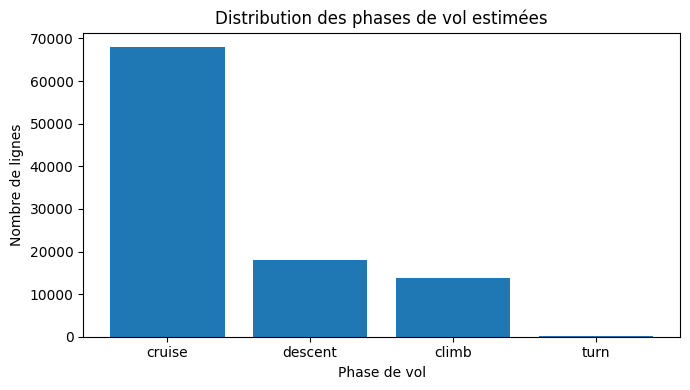

In [ ]:
plt.figure(figsize=(7, 4))

plt.bar(
    flight_phase_counts["flight_phase"],
    flight_phase_counts["count"]
)

plt.xlabel("Phase de vol")
plt.ylabel("Nombre de lignes")
plt.title("Distribution des phases de vol estimées")
plt.tight_layout()
plt.show()

# 10. Visualisation simple d’une trajectoire avec features

Nous visualisons quelques features sur une trajectoire.

L’objectif est de vérifier qualitativement que les nouvelles variables évoluent de manière cohérente.

In [ ]:
# Choisir une trajectoire longue pour la visualisation
trajectory_lengths = df_features.groupby("trajectory_id").size()

example_trajectory_id = trajectory_lengths.sort_values(ascending=False).index[0]

print("Trajectory_id choisi :", example_trajectory_id)
print("Nombre de points :", trajectory_lengths.loc[example_trajectory_id])

Trajectory_id choisi : 01012b_1
Nombre de points : 1519


In [ ]:
# Extraire cette trajectoire
traj_example = df_features[
    df_features["trajectory_id"] == example_trajectory_id
].sort_values("datetime")

display(traj_example.head())

,datetime,icao24,trajectory_id,lat,lon,altitude,velocity,heading,vertrate,time_diff_sec,dt_sec,ground_speed_ms,vertical_rate_fpm,acceleration,turn_rate,vx_ms,vy_ms,vz_ms,heading_sin,heading_cos,distance_step_m,distance_traveled_m,trajectory_angle,distance_destination_m,elapsed_time_sec,roll_mean_velocity,roll_std_velocity,roll_mean_altitude,roll_std_altitude,roll_mean_vertrate,roll_std_vertrate,roll_mean_acceleration,roll_std_acceleration,roll_mean_turn_rate,roll_std_turn_rate,roll_mean_distance_step_m,roll_std_distance_step_m,flight_phase
24486,2017-07-03 10:00:10+00:00,01012b,01012b_1,41.206830,23.586647,10088.88,266.64780,333.28665,0.0,NaN,10.0,266.64780,0.0,0.000000,0.000000,-119.865456,238.18758,0.0,-0.449527,0.893267,0.0000,0.0000,333.28665,3304758.8,0.0,266.64780,0.000000,10088.88,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0000,0.0000,cruise
24487,2017-07-03 10:00:20+00:00,01012b,01012b_1,41.228664,23.572104,10088.88,266.64780,333.28665,0.0,10.0,10.0,266.64780,0.0,0.000000,0.000000,-119.865456,238.18758,0.0,-0.449527,0.893267,2715.4644,2715.4644,333.38947,3302195.5,10.0,266.64780,0.000000,10088.88,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,1357.7322,1920.1233,cruise
24488,2017-07-03 10:00:30+00:00,01012b,01012b_1,41.248543,23.558807,10088.88,266.18835,333.23688,0.0,10.0,10.0,266.18835,0.0,-0.045944,-0.004978,-119.865456,237.67313,0.0,-0.450303,0.892876,2474.1572,5189.6216,333.30283,3299859.2,20.0,266.49466,0.265255,10088.88,0.0,0.0,0.0,-0.015315,0.026526,-0.001659,0.002874,1729.8739,1502.9655,cruise
24489,2017-07-03 10:00:40+00:00,01012b,01012b_1,41.271194,23.543701,10088.88,265.72913,333.18692,0.0,10.0,10.0,265.72913,0.0,-0.045923,-0.004995,-119.865456,237.15869,0.0,-0.451081,0.892483,2817.6787,8007.3003,333.38092,3297200.0,30.0,266.30325,0.439788,10088.88,0.0,0.0,0.0,-0.022967,0.026520,-0.002493,0.002879,2001.8251,1342.2990,cruise
24490,2017-07-03 10:00:50+00:00,01012b,01012b_1,41.292480,23.529419,10088.88,265.03802,333.23600,0.0,10.0,10.0,265.03802,0.0,-0.069109,0.004909,-119.351006,236.64424,0.0,-0.450317,0.892869,2650.7466,10658.0470,333.24683,3294696.8,40.0,266.05023,0.682073,10088.88,0.0,0.0,0.0,-0.032195,0.030875,-0.001013,0.004144,2131.6094,1198.1422,cruise


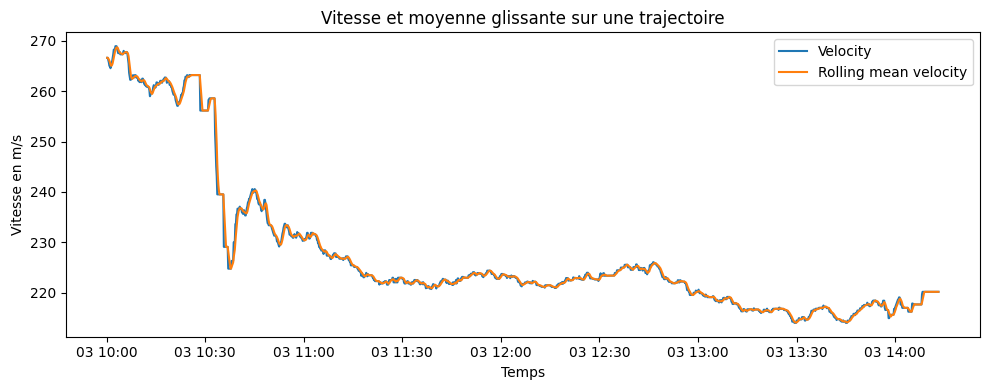

In [ ]:
plt.figure(figsize=(10, 4))

plt.plot(
    traj_example["datetime"],
    traj_example["velocity"],
    label="Velocity"
)

plt.plot(
    traj_example["datetime"],
    traj_example["roll_mean_velocity"],
    label="Rolling mean velocity"
)

plt.xlabel("Temps")
plt.ylabel("Vitesse en m/s")
plt.title("Vitesse et moyenne glissante sur une trajectoire")
plt.legend()
plt.tight_layout()
plt.show()

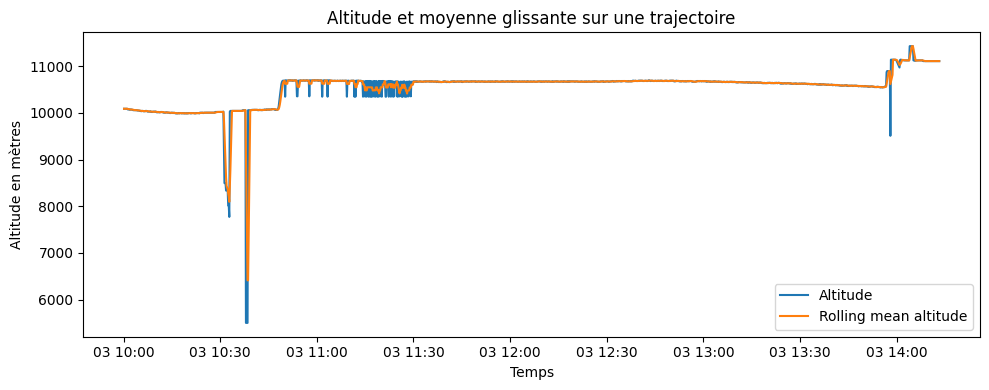

In [ ]:
plt.figure(figsize=(10, 4))

plt.plot(
    traj_example["datetime"],
    traj_example["altitude"],
    label="Altitude"
)

plt.plot(
    traj_example["datetime"],
    traj_example["roll_mean_altitude"],
    label="Rolling mean altitude"
)

plt.xlabel("Temps")
plt.ylabel("Altitude en mètres")
plt.title("Altitude et moyenne glissante sur une trajectoire")
plt.legend()
plt.tight_layout()
plt.show()

# 11. Validation finale du dataset features

Avant de sauvegarder le fichier final, nous vérifions que le dataset est prêt pour la suite.

Nous contrôlons :

- la présence des colonnes principales ;
- l’absence de NaN critiques ;
- l’absence de valeurs infinies ;
- la présence des trajectoires ;
- la cohérence des variables principales.

In [ ]:
# Colonnes critiques après feature engineering
critical_feature_columns = [
    "datetime",
    "icao24",
    "trajectory_id",
    "lat",
    "lon",
    "altitude",
    "velocity",
    "heading",
    "vertrate",
    "ground_speed_ms",
    "vertical_rate_fpm",
    "acceleration",
    "turn_rate",
    "distance_step_m",
    "distance_traveled_m",
    "trajectory_angle",
    "distance_destination_m",
    "flight_phase"
]

# Vérifier les colonnes manquantes
missing_critical_features = [
    col for col in critical_feature_columns
    if col not in df_features.columns
]

if len(missing_critical_features) == 0:
    print("OK : toutes les colonnes critiques sont présentes.")
else:
    print("PROBLÈME : colonnes critiques manquantes :")
    print(missing_critical_features)

OK : toutes les colonnes critiques sont présentes.


In [ ]:
# Vérifier les NaN dans les colonnes critiques
missing_critical_values = df_features[critical_feature_columns].isna().sum()

display(missing_critical_values)

if missing_critical_values.sum() == 0:
    print("OK : aucune valeur manquante dans les colonnes critiques.")
else:
    print("Attention : certaines colonnes critiques contiennent des valeurs manquantes.")

,0
datetime,0
icao24,0
trajectory_id,0
lat,0
lon,0
altitude,0
velocity,0
heading,0
vertrate,0
ground_speed_ms,0


OK : aucune valeur manquante dans les colonnes critiques.


In [ ]:
# Résumé final du dataset features
print("Résumé final du dataset features")
print("--------------------------------")
print("Nombre de lignes :", f"{len(df_features):,}")
print("Nombre de colonnes :", df_features.shape[1])
print("Nombre d'avions :", f"{df_features['icao24'].nunique():,}")
print("Nombre de trajectoires :", f"{df_features['trajectory_id'].nunique():,}")
print("Période :", df_features["datetime"].min(), "→", df_features["datetime"].max())

Résumé final du dataset features
--------------------------------
Nombre de lignes : 100,000
Nombre de colonnes : 38
Nombre d'avions : 154
Nombre de trajectoires : 342
Période : 2017-07-03 10:00:10+00:00 → 2017-07-03 17:59:50+00:00


# 12. Sauvegarde d’un résumé du feature engineering

Nous sauvegardons un résumé simple de cette étape.

Ce résumé pourra être utilisé dans le rapport.

In [ ]:
# Créer le dossier metrics si nécessaire
METRICS_DIR.mkdir(parents=True, exist_ok=True)

# Résumé du feature engineering
feature_engineering_summary = {
    "input_file": str(resampled_path),
    "output_file": str(features_output_path),
    "output_rows_total": n_total_lines,
    "sample_rows_checked": len(df_features),
    "input_columns": df_resampled.shape[1],
    "output_columns": df_features.shape[1],
    "n_created_features": len(created_features),
    "sample_aircraft": df_features["icao24"].nunique(),
    "sample_trajectories": df_features["trajectory_id"].nunique(),
    "sample_start_datetime": df_features["datetime"].min(),
    "sample_end_datetime": df_features["datetime"].max()
}

feature_engineering_summary_df = pd.DataFrame([feature_engineering_summary])

display(feature_engineering_summary_df)

# Chemin du résumé
feature_summary_path = METRICS_DIR / "feature_engineering_summary.csv"

# Sauvegarde
feature_engineering_summary_df.to_csv(feature_summary_path, index=False)

print("Résumé du feature engineering sauvegardé avec succès.")
print("Chemin :", feature_summary_path)

,input_file,output_file,output_rows_total,sample_rows_checked,input_columns,output_columns,n_created_features,sample_aircraft,sample_trajectories,sample_start_datetime,sample_end_datetime
0,/content/drive/MyDrive/aircraft-trajectory-pre...,/content/drive/MyDrive/aircraft-trajectory-pre...,11924978,100000,10,38,28,154,342,2017-07-03 10:00:10+00:00,2017-07-03 17:59:50+00:00


Résumé du feature engineering sauvegardé avec succès.
Chemin : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/feature_engineering_summary.csv


In [ ]:
# Chemin du résumé
feature_summary_path = METRICS_DIR / "feature_engineering_summary.csv"

# Sauvegarde
feature_engineering_summary_df.to_csv(feature_summary_path, index=False)

print("Résumé du feature engineering sauvegardé avec succès.")
print("Chemin :", feature_summary_path)

Résumé du feature engineering sauvegardé avec succès.
Chemin : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/feature_engineering_summary.csv


# 13. Vérification du fichier sauvegardé

Nous relisons rapidement le fichier sauvegardé pour vérifier qu’il est bien accessible.

In [ ]:
# Relecture rapide du fichier sauvegardé
df_check = pd.read_csv(features_output_path, nrows=5)

display(df_check)

,datetime,icao24,trajectory_id,lat,lon,altitude,velocity,heading,vertrate,time_diff_sec,dt_sec,ground_speed_ms,vertical_rate_fpm,acceleration,turn_rate,vx_ms,vy_ms,vz_ms,heading_sin,heading_cos,distance_step_m,distance_traveled_m,trajectory_angle,distance_destination_m,elapsed_time_sec,roll_mean_velocity,roll_std_velocity,roll_mean_altitude,roll_std_altitude,roll_mean_vertrate,roll_std_vertrate,roll_mean_acceleration,roll_std_acceleration,roll_mean_turn_rate,roll_std_turn_rate,roll_mean_distance_step_m,roll_std_distance_step_m,flight_phase
0,2017-07-03 11:40:20+00:00,1,000001_1,51.997684,6.827689,99.06,35.436940,279.18884,-0.32512,NaN,10.0,35.436940,-63.99987,0.000000,0.000000,-34.982193,5.658884,-0.32512,-0.987167,0.159689,0.00000,0.00000,279.18884,193340.31,0.0,35.436940,0.000000,99.060,0.000000,-0.32512,0.0,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,cruise
1,2017-07-03 11:40:30+00:00,1,000001_1,51.997173,6.820391,243.84,34.494610,252.64598,-0.32512,10.0,10.0,34.494610,-63.99987,-0.094233,-2.654286,-32.924416,-10.288880,-0.32512,-0.954480,-0.298275,502.87653,502.87653,263.50140,192883.56,10.0,34.965775,0.666327,171.450,102.374916,-0.32512,0.0,-0.047116,0.066633,-1.327143,1.876864,251.43826,355.58740,turn
2,2017-07-03 11:40:40+00:00,1,000001_1,51.996185,6.816864,243.84,33.972786,237.99461,-0.32512,10.0,10.0,33.972786,-63.99987,-0.052183,-1.465136,-28.808865,-18.005540,-0.32512,-0.847998,-0.529999,265.30624,768.18274,245.52727,192620.11,20.0,34.634777,0.742073,195.580,83.588776,-0.32512,0.0,-0.048805,0.047207,-1.373141,1.329532,256.06090,251.56570,cruise
3,2017-07-03 11:40:50+00:00,1,000001_1,51.996185,6.816864,243.84,34.066140,231.74557,-0.32512,10.0,10.0,34.066140,-63.99987,0.009335,-0.624904,-26.751087,-21.092203,-0.32512,-0.785269,-0.619155,0.00000,768.18274,0.00000,192620.11,30.0,34.492620,0.669293,207.645,72.390000,-0.32512,0.0,-0.034270,0.048278,-1.186081,1.148217,192.04568,242.03719,cruise
4,2017-07-03 11:41:00+00:00,1,000001_1,51.991837,6.809463,281.94,35.436940,230.30093,-0.32512,10.0,10.0,35.436940,-63.99987,0.137080,-0.144465,-27.265532,-22.635536,-0.32512,-0.769410,-0.638755,700.40690,1468.58970,226.34131,191936.06,40.0,34.681484,0.717156,222.504,70.951980,-0.32512,0.0,0.000000,0.087294,-0.977758,1.098087,293.71793,309.22925,cruise


# 14. Conclusion de la partie Feature Engineering

Dans cette partie, nous avons créé des features temporelles et géométriques à partir du fichier resamplé.

Nous avons utilisé comme entrée :

`data/interim/resampled_all_8h.csv`

Puis nous avons créé plusieurs groupes de features :

## Features cinématiques

- `ground_speed_ms`
- `vertical_rate_fpm`
- `acceleration`
- `turn_rate`

Ces variables décrivent la vitesse, la montée/descente, l’accélération et les virages de l’avion.

## Features géométriques

- `distance_step_m`
- `distance_traveled_m`
- `trajectory_angle`
- `distance_destination_m`

Ces variables décrivent le déplacement spatial de l’avion.

## Features de direction

- `heading_sin`
- `heading_cos`
- `vx_ms`
- `vy_ms`
- `vz_ms`

Ces variables permettent de mieux représenter la direction et le mouvement.

## Rolling features

Nous avons calculé des moyennes et écarts-types glissants sur plusieurs variables.

Ces features permettent de capturer la tendance récente du mouvement.

## Phase de vol estimée

Nous avons créé la colonne :

`flight_phase`

avec les classes :

- `climb`
- `descent`
- `turn`
- `cruise`

## Fichier produit

Le fichier final est :

`data/processed/features_clean.csv`

Ce fichier est maintenant prêt pour le notebook Machine Learning.

## Prochaine étape

Dans le notebook suivant :

`03_ml_models.ipynb`

nous allons :

1. charger `features_clean.csv` ;
2. créer les targets futures :
   - `lat_future`
   - `lon_future`
   - `altitude_future`
3. créer `X` et `y` ;
4. faire le split train / validation / test ;
5. entraîner les modèles ML.

La normalisation et la PCA ne sont pas faites ici.

Elles seront réalisées plus tard dans le notebook ML, après la création des targets et le split train/validation/test, afin d’éviter toute fuite de données.